In [3]:
import deeplay as dl
import deeptrack as dt
import numpy as np
import matplotlib.pyplot as plt
from skimage import morphology as skmorph
import torch
from PIL import Image
import os

/Users/mario/anaconda3/envs/NN/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
import tifffile
import matplotlib.pyplot as plt
import numpy as np
import readlif.reader as lif_reader
#he passat LIF-1-Sèrie 003 a format TIF amb el programa Fiji perquè no em deixava llegir-ho com a LIF. He agafat la sèrie 3 perquè considero que era la que es veia millor.
#les sèries 01 i 02 considero que son les sèries de beads per calibratge, alguna deu ser algun control? DUBTE
lif_file = "/Users/mario/Desktop/UVic/SPT/Projecte Laura/20241026  Project 1  E1E2 HiLO.lif"
reader = lif_reader.LifFile(lif_file)
img = reader.get_image(3)  # Get the third image (0-indexed)
print(f'File: {lif_file}')
print(f'Number of images in the LIF file: {reader.num_images}\n')
print("Tipus de dades de la imatge:", type(img))
for i, img in enumerate(reader.get_iter_image()):
    print(f"Forma de la imatge {i}:", type(img))


File: /Users/mario/Desktop/UVic/SPT/Projecte Laura/20241026  Project 1  E1E2 HiLO.lif
Number of images in the LIF file: 6

Tipus de dades de la imatge: <class 'readlif.reader.LifImage'>
Forma de la imatge 0: <class 'readlif.reader.LifImage'>
Forma de la imatge 1: <class 'readlif.reader.LifImage'>
Forma de la imatge 2: <class 'readlif.reader.LifImage'>
Forma de la imatge 3: <class 'readlif.reader.LifImage'>
Forma de la imatge 4: <class 'readlif.reader.LifImage'>
Forma de la imatge 5: <class 'readlif.reader.LifImage'>


[0] Series002 | dims=Dims(x=1200, y=512, z=1, t=500, m=1) | canales=1 | bits=(12,)
[1] Series001 | dims=Dims(x=1200, y=512, z=1, t=500, m=1) | canales=1 | bits=(12,)
[2] Series003 | dims=Dims(x=1200, y=512, z=1, t=500, m=1) | canales=1 | bits=(12,)
[3] Series004 | dims=Dims(x=1200, y=512, z=1, t=500, m=1) | canales=1 | bits=(12,)
[4] Imatge Inicial beads | dims=Dims(x=1200, y=1200, z=1, t=1, m=1) | canales=2 | bits=(12, 12)
[5] BF | dims=Dims(x=1200, y=1200, z=1, t=1, m=1) | canales=1 | bits=(12,)
Forma del vídeo: (500, 512, 1200)


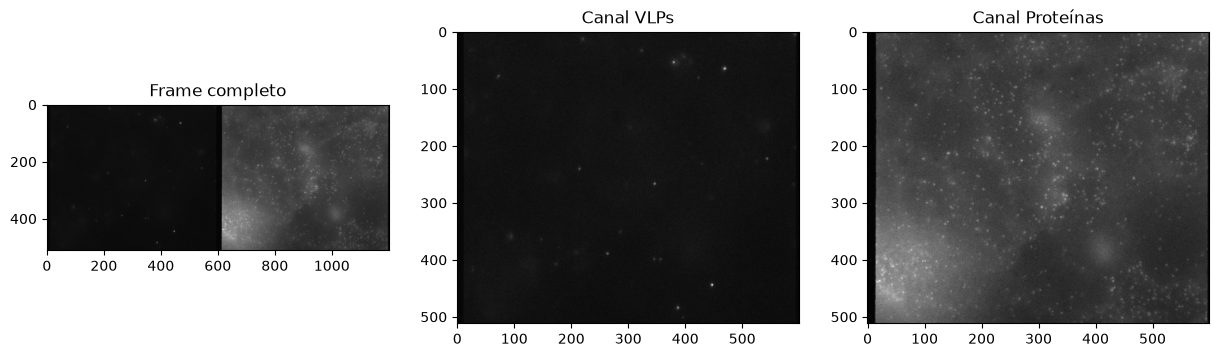

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from readlif.reader import LifFile

lif_file = "/Users/mario/Desktop/UVic/SPT/Projecte Laura/20241026  Project 1  E1E2 HiLO.lif"
reader = LifFile(lif_file)

# 1) Inspeccionar qué contiene cada serie
for i, im in enumerate(reader.get_iter_image()):
    print(f"[{i}] {im.name} | dims={im.dims} | canales={im.channels} | bits={im.bit_depth}")

# 2) Elegir la serie (índice 0 = primera serie)
img = reader.get_image(2)   # "Sèrie 003" -> índice 2 (compruébalo con el print de arriba)

# 3) Convertir a array numpy: (t, y, x) para el canal 0
n_t = img.dims.t
video = np.stack([np.array(f) for f in img.get_iter_t(c=0, z=0)])
print("Forma del vídeo:", video.shape)   # (num_frames, altura, amplada)

# 4) Primer frame y separación de canales
frame = video[0]
altura, amplada_total = frame.shape
ample_canal = amplada_total // 2
vlp_channel = frame[:, :ample_canal]        # izquierda: VLP
proteines_channel = frame[:, ample_canal:]  # derecha: proteínas

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(frame, cmap='gray');            ax[0].set_title("Frame completo")
ax[1].imshow(vlp_channel, cmap='gray');      ax[1].set_title("Canal VLPs")
ax[2].imshow(proteines_channel, cmap='gray'); ax[2].set_title("Canal Proteínas")
plt.show()

**TROBO LES COORDENADES DELS VLP**

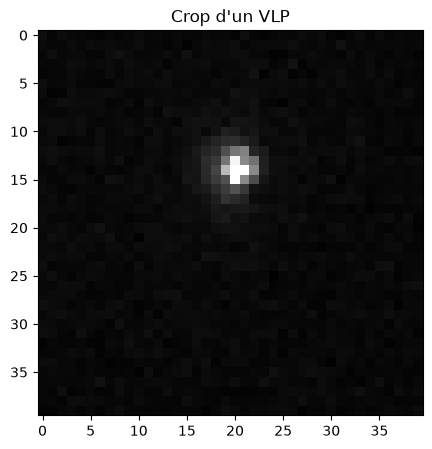

Mínima: 105, Màxima: 848, Mitjana: 137.55625


In [6]:
#observo paràmetres d'un VLP. Aquestes coordenades les he trobat amb el punter de Fiji
y0, x0  = 450, 447
crop_size = 40
half_sz = crop_size // 2
vlp_crop = vlp_channel[y0 - half_sz : y0 + half_sz, x0 - half_sz : x0 + half_sz]

import matplotlib.pyplot as plt

plt.figure(figsize=(5, 5))
plt.imshow(vlp_crop, cmap='gray')
plt.title(f"Crop d'un VLP")
plt.show()

print(f"Mínima: {vlp_crop.min()}, Màxima: {vlp_crop.max()}, Mitjana: {vlp_crop.mean()}")

In [7]:
#simulació d'imatges d'aquest punt, així entrem la IA
import deeptrack as dt
import numpy as np

optics = dt.Fluorescence(  #amb això simulen el microoscopi
    wavelength=600 * dt.units.nm, NA=0.9, magnification=1.5,
    resolution=0.07 * dt.units.um, output_region=(0, 0, 50, 50),)
particle = dt.Sphere(radius=0.13 * dt.units.um, position=(25, 25), intensity=12000, z=0) #amb això simulem UN sol punt
sim_im_pip = optics(particle) >> dt.Add(30) >> np.random.poisson >> dt.Add(82)

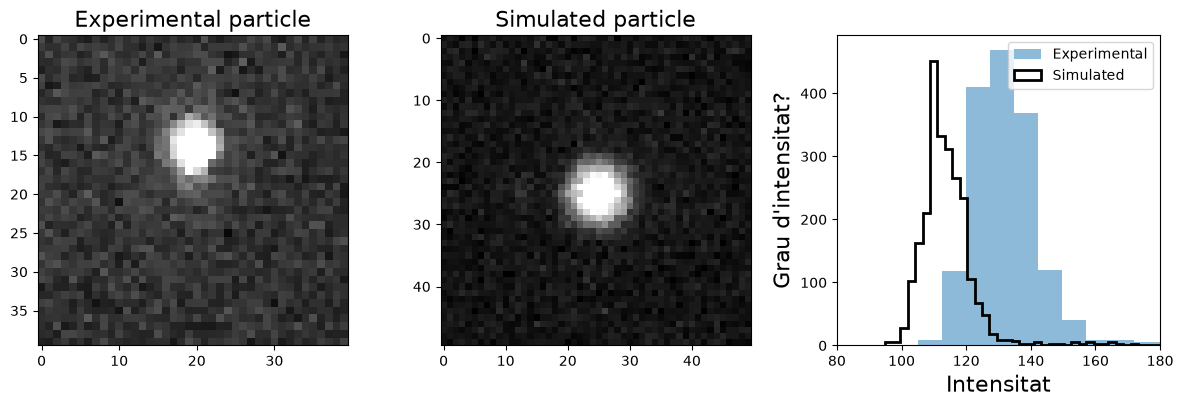

In [8]:
#comparem la imatge real vs la simulada
sim_im = sim_im_pip()

# codi per dibuixar les dues imatges i histogrames
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(vlp_crop, cmap="gray", vmin=100, vmax=250)
plt.title("Experimental particle", fontsize=16)

plt.subplot(1, 3, 2)
plt.imshow(sim_im, cmap="gray", vmin=100, vmax=250)
plt.title("Simulated particle", fontsize=16)

plt.subplot(1, 3, 3)
plt.hist(np.array(vlp_crop).flatten(), bins=100, label="Experimental", alpha=0.5)
plt.hist(np.array(sim_im).flatten(), bins=100, label="Simulated",
         histtype="step", color="black", linewidth=2)
plt.xlabel("Intensitat", fontsize=16)
plt.xlim([80, 180])
plt.ylabel("Grau d'intensitat?", fontsize=16)
plt.legend()

plt.tight_layout()
plt.show()

#la particula simulada la veig be pero el gràfic té moltes diferències, això pot afectar després

massa diferència d'intensitat encara que ho modifiqui segueix sent bastant diferent

In [9]:
optics = dt.Fluorescence(
    wavelength=600 * dt.units.nm, NA=0.9, magnification=1,
    resolution=0.1 * dt.units.um, output_region=(0, 0, 128, 128),)
particle = dt.Sphere(
    radius=0.15 * dt.units.um,
    position=lambda: np.random.uniform(0, 128, size=2),
    intensity=lambda: np.random.uniform(.5e3, 1.5e3),
    z=lambda: np.random.uniform(-0.5, 0.5) * dt.units.um,)
postprocess = (dt.Add(lambda: np.random.uniform(20, 40)) >> np.random.poisson
               >> dt.Add(lambda: np.random.uniform(70, 90)))
normalization = dt.AsType("float") >> dt.Subtract(110) >> dt.Divide(250)
particles = particle ^ (lambda: np.random.randint(10, 20))
sim_im_pip = optics(particles) >> postprocess >> normalization

Màscara amb get_mask - min: 0.0, max: 1.0


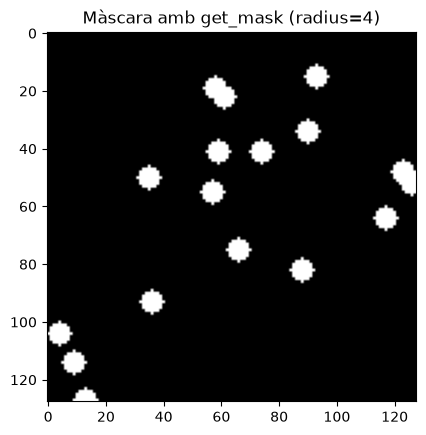

In [10]:
from skimage import morphology as skmorph

def get_mask(radius):
    def inner(mask):
        mask = np.sum(mask, -1, keepdims=True) > 0
        mask = np.pad(mask, [(radius+2, radius+2), (radius+2, radius+2), (0, 0)], mode="constant")
        mask = skmorph.isotropic_dilation(mask, radius=radius)
        return mask[2:-2, 2:-2]
    return inner

sim_mask_pip = (particles
                >> dt.SampleToMasks(get_mask, radius=4,
                                    output_region=optics.output_region,
                                    merge_method="or")
                >> dt.AsType("float"))

sim_mask = sim_mask_pip()

print(f"Màscara amb get_mask - min: {sim_mask.min()}, max: {sim_mask.max()}")
plt.imshow(sim_mask, cmap="gray")
plt.title("Màscara amb get_mask (radius=4)")
plt.show()

ENTRENEM LA UNET

Regressor(
  (loss): BCEWithLogitsLoss()
  (optimizer): Adam[Adam]()
  (train_metrics): MetricCollection,
    prefix=train
  )
  (val_metrics): MetricCollection,
    prefix=val
  )
  (test_metrics): MetricCollection,
    prefix=test
  )
  (model): UNet2d(
    (encoder): ConvolutionalEncoder2d(
      (blocks): LayerList(
        (0): Conv2dBlock(
          (layer): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (activation): ReLU()
        )
        (1): Conv2dBlock(
          (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
          (layer): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
          (activation): ReLU()
        )
      )
      (postprocess): Identity()
    )
    (bottleneck): ConvolutionalNeuralNetwork(
      (blocks): LayerList(
        (0): Conv2dBlock(
          (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
          (layer): Conv2d(64, 64, kernel_siz

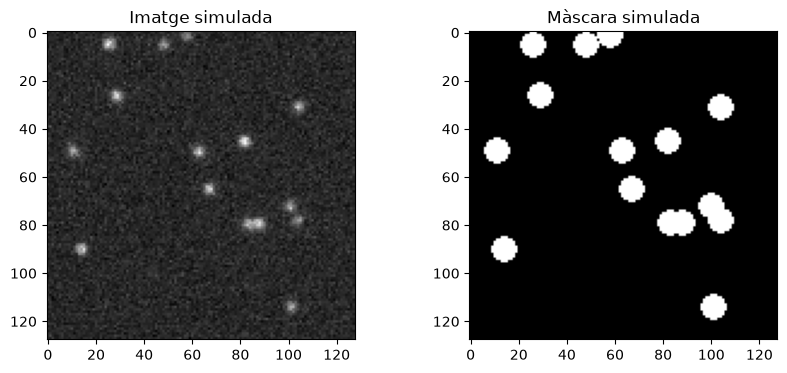

In [11]:
import deeplay as dl
import torch
unet = dl.UNet2d(in_channels=1, channels=[32, 64], out_channels=1)
unet_reg = dl.Regressor(
    model=unet, loss=torch.nn.BCEWithLogitsLoss(), optimizer=dl.Adam(),
).create()
print(unet_reg)
pipeline = (sim_im_pip & sim_mask_pip)
pipeline.update()
result = pipeline()

sim_im = result[0]
sim_mask = result[1]

sim_mask_2d = sim_mask[:, :, 0]

print(f"Forma imatge: {sim_im.shape}")
print(f"Forma màscara: {sim_mask.shape}")
print(f"Màscara - min: {sim_mask_2d.min():.4f}, max: {sim_mask_2d.max():.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(sim_im, cmap="gray")
plt.title("Imatge simulada")
plt.subplot(1, 2, 2)
plt.imshow(sim_mask_2d, cmap="gray")
plt.title("Màscara simulada")
plt.show()

In [12]:
#l'entrenem
sim_im_mask_pip = ((sim_im_pip & sim_mask_pip) >> dt.MoveAxis(2, 0) >> dt.pytorch.ToTensor(dtype=torch.float))
# abans era: sim_im_mask_pip = sim_im_pip & sim_mask_pip
train_dataset = dt.pytorch.Dataset(sim_im_mask_pip, length=320, replace=.1)
data_loader = dl.DataLoader(train_dataset, batch_size=32)
unet_trainer = dl.Trainer(max_epochs=20, accelerator="auto")    #cambiar a 20
unet_trainer.fit(unet_reg, data_loader)

/Users/mario/anaconda3/envs/NN/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/logger_connector/logger_connector.py:76: Starting from v1.9.0, `tensorboardX` has been removed as a dependency of the `lightning.pytorch` package, due to potential conflicts with other packages in the ML ecosystem. For this reason, `logger=True` will use `CSVLogger` as the default logger, unless the `tensorboard` or `tensorboardX` packages are found. Please `pip install lightning[extra]` or one of them to enable TensorBoard support by default
/Users/mario/anaconda3/envs/NN/lib/python3.14/site-packages/lightning/pytorch/trainer/configuration_validator.py:70: You defined a `validation_step` but have no `val_dataloader`. Skipping val loop.


┏━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name          ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ loss          │ BCEWithLogitsLoss │      0 │ train │     0 │
│ 1 │ train_metrics │ MetricCollection  │      0 │ train │     0 │
│ 2 │ val_metrics   │ MetricCollection  │      0 │ train │     0 │
│ 3 │ test_metrics  │ MetricCollection  │      0 │ train │     0 │
│ 4 │ model         │ UNet2d            │  113 K │ train │     0 │
│ 5 │ optimizer     │ Adam              │      0 │ train │     0 │
└───┴───────────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 113 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 113 K                                                                                                
Total estimated model params size (MB): 0.455                                                                      
Modules in train mode: 34                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

/Users/mario/anaconda3/envs/NN/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/Users/mario/anaconda3/envs/NN/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=7` in the `DataLoader` to improve performance.
/Users/mario/anaconda3/envs/NN/lib/python3.14/site-packages/lightning/pytorch/loops/fit_loop.py:321: The number of training batches (10) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if you want to see logs for the training epoch.


Epoch 19: 100%|██████████| 10/10 [00:29<00:00,  0.34it/s, v_num=2, train_loss_step=0.0365, train_loss_epoch=0.0376]


In [13]:
import skimage as sk

def mask_to_positions(mask):
    "Convert binary mask to centroid array"
    labels = sk.measure.label(mask)
    props = sk.measure.regionprops(labels)
    return np.array([prop.centroid for prop in props])

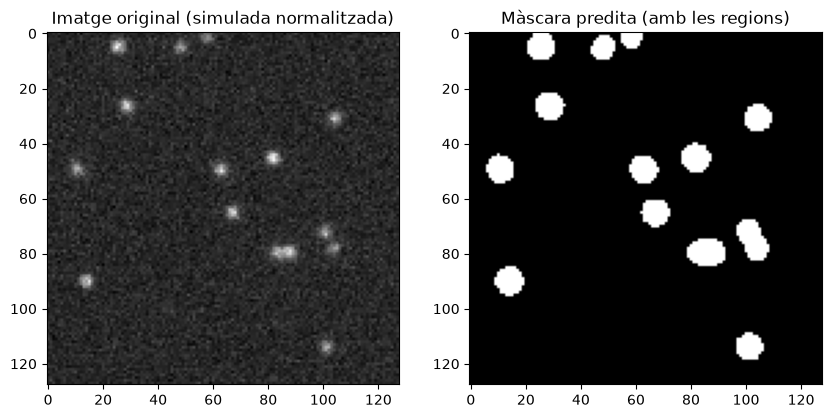

In [14]:
#li fiquem la imatge i que ella fagi els punts + regions
image_of_particles = sim_im

image_of_particles_reshaped = np.moveaxis(image_of_particles, -1, 0)
image_of_particles_tensor = torch.from_numpy(
    image_of_particles_reshaped.astype(np.float32)
).unsqueeze(0)

pred_mask = unet_reg(image_of_particles_tensor).detach()
pred_mask = torch.nn.functional.sigmoid(pred_mask)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(image_of_particles[:, :, 0], cmap="gray")
plt.title("Imatge original (simulada normalitzada)")
plt.subplot(1, 2, 2)
plt.imshow(pred_mask[0, 0, ...] > 0.7, cmap="gray")
plt.title("Màscara predita (amb les regions)")
plt.show()

podria ser millor la veritat, no és del tot exacte

In [15]:
import scipy.io as sio
import numpy as np

mat = sio.loadmat('/content/transformation.mat')

affine_matrix = mat['None'].T

print("Matriu de transformació:")
print(affine_matrix)

FileNotFoundError: [Errno 2] No such file or directory: '/content/transformation.mat'

In [16]:
import tifffile
from skimage.measure import label, regionprops
import torch
import csv
import numpy as np

tif_file = '/content/SERIE 03.tif'
video = tifffile.imread(tif_file)

#dimensions?
if len(video.shape) == 2:  #2D?
    processed_frames = [video]
    total_frames_to_process = 1
elif len(video.shape) == 3:  #3D?
    processed_frames = video
    total_frames_to_process = video.shape[0]
else:
    raise ValueError("Unexpected video shape: " + str(video.shape))


fons_mitja = 100.0
fons_std = 30.0

def normalize_frame(frame, mean, std):
    return (frame.astype(np.float32) - mean) / (std * 2)

unet_reg.eval()
vlp_coords = []

for t_idx, current_frame in enumerate(processed_frames):

    vlp_raw = current_frame[:, :600]  #canal esquerre (VLPs)
    vlp_norm = normalize_frame(vlp_raw, fons_mitja, fons_std)
    vlp_tensor = torch.from_numpy(vlp_norm).unsqueeze(0).unsqueeze(0).float()

    with torch.no_grad():
        pred = unet_reg(vlp_tensor)
        mask = torch.sigmoid(pred).squeeze().cpu().numpy() > 0.7

    lab = label(mask)
    props = regionprops(lab)
    for prop in props:
        y, x = prop.centroid
        vlp_coords.append((t_idx, y, x))

    if t_idx % 50 == 0:
        print(f"Processat frame {t_idx}/{total_frames_to_process}")

print(f"Total VLPs detectats: {len(vlp_coords)}")


with open('vlp_coords.csv', 'w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(['frame', 'y', 'x'])
    writer.writerows(vlp_coords)

print("Coordenades guardades a vlp_coords.csv")

FileNotFoundError: [Errno 2] No such file or directory: '/content/SERIE 03.tif'

14 vlps? nomes? suposo que serà de la mascarà

In [16]:
!pip install trackpy

import pandas as pd
import trackpy as tp

df = pd.read_csv('vlp_coords.csv')
traj = tp.link(df, search_range=10, memory=5)
print(f"Nombre de trajectòries VLPs: {traj['particle'].nunique()}")
traj.to_csv('vlp_trajectories.csv', index=False)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.5/133.5 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for trackpy: filename=trackpy-0.7-py3-none-any.whl size=130480 sha256=b4de17aa99be30c76244689e91f9c1121d7db98a6a133858068e46f8ceb45585
  Stored in directory: /root/.cache/pip/wheels/35/97/08/ded65bf12054e510a946f888e0bbaf9d698e449eb365791b94
Successfully built trackpy
Nombre de trajectòries VLPs: 14


COMBINACIÓ VLPs i PROTEINES

In [17]:
import numpy as np
import pandas as pd
import scipy.io as sio
import csv
import trackpy as tp


In [18]:
import numpy as np
T = np.array([[-0.5479, -0.6109, 0],
              [ 0.2547,  2.5512, 0],
              [500.5556, 31.2281, 1]])

In [19]:
tform_raw_data = mat['None'].T
tform_var = tform_raw_data[0][3]
print("Tipus de 'tform':", type(tform_var))
print("Forma de 'tform':", tform_var.shape)     #això m'ho ha arreglat el gemini, no sé per què tform no funciona eperò tform_var sí
#potser es un array estructural, ho miro:
if hasattr(tform_var, 'dtype'):
    print("Camps de l'estructura:", tform_var.dtype.names)

Tipus de 'tform': <class 'numpy.ndarray'>
Forma de 'tform': (6, 1)
Camps de l'estructura: None


In [20]:
import scipy.io as sio
import pandas as pd
import numpy as np

# Load tracksFinal here, as it was not defined when this cell ran
mat_track = sio.loadmat('/content/20241026  Project 1  E1E2 HiLO_s03_tracking.mat')
tracksFinal = mat_track['tracksFinal']

all_tracks = []   #faig llistat de tuples (track_id, frame, y, x)

for i in range(tracksFinal.shape[0]): # Corrected from 'all_tracks.shape[0]' or 'tracksfinal.shape[0]'
    track = tracksFinal[i, 0]
    camp_coords = track['tracksCoordAmpCG']   # array (1, N)

    if camp_coords.size == 0:
        continue

    #n frames 8
    coords = camp_coords.reshape(-1, 8)
    n_frames = coords.shape[0]

    for f in range(n_frames):
        x = coords[f, 0]
        y = coords[f, 1]
        all_tracks.append((i, f, y, x))   #track_id, frame, y, x

df_prot = pd.DataFrame(all_tracks, columns=['track_id', 'frame', 'y', 'x'])
print("Proteïnes carregades:", len(df_prot))

Proteïnes carregades: 168064


In [21]:
track0 = tracksFinal[0, 0]
print("Tipus de track0:", type(track0))
print("Camps:", track0.dtype.names)

#trackscoord mo ha dit el gemini, no sabia com ferho
camp_coords = track0['tracksCoordAmpCG']
print("\nTipus de camp_coords:", type(camp_coords))
print("Forma de camp_coords:", camp_coords.shape if hasattr(camp_coords, 'shape') else 'no shape')
print("Contingut (resum):", camp_coords)

Tipus de track0: <class 'numpy.void'>
Camps: ('tracksFeatIndxCG', 'tracksCoordAmpCG', 'seqOfEvents')

Tipus de camp_coords: <class 'numpy.ndarray'>
Forma de camp_coords: (1, 4000)
Contingut (resum): [[1.48776441e+02 3.64622768e+02 0.00000000e+00 ... 8.13324624e-02
  0.00000000e+00 1.21504526e-03]]


les coordenades del mario son en linia i no en matriu, així que ho paso a matriu:

In [22]:
#CARREGO PROTES AL TRACKING ORIGINAL
mat_track = sio.loadmat('/content/20241026  Project 1  E1E2 HiLO_s03_tracking.mat')
tracksFinal = mat_track['tracksFinal']

all_tracks = []

for i in range(tracksFinal.shape[0]):
    track = tracksFinal[i, 0]
    camp_coords = track['tracksCoordAmpCG']

    if camp_coords.size == 0:
        continue   # trajectòria buida, la ignoro

    coords = camp_coords.reshape(-1, 8)
    n_frames = coords.shape[0]

    for f in range(n_frames):
        x = coords[f, 0]
        y = coords[f, 1]
        all_tracks.append((i, f, y, x))   # track_id, frame, y, x

df_prot = pd.DataFrame(all_tracks, columns=['track_id', 'frame', 'y', 'x'])
print("Proteïnes carregades"), len(df_prot)


#APLICO CADA TRANFORMACIO A CADA COORDENADA DE PROTE
import numpy as np

T = np.array([[-0.5479, -0.6109, 0],
              [ 0.2547,  2.5512, 0],
              [500.5556, 31.2281, 1]])

def transformar(x, y, T):
    """Aplica la transformació afí a un punt (x,y)."""
    p = np.array([x, y, 1])
    p_trans = T @ p
    return p_trans[0], p_trans[1]
x_trans = []
y_trans = []
for x, y in zip(df_prot['x'], df_prot['y']):
    xt, yt = transformar(x, y, T)
    x_trans.append(xt)
    y_trans.append(yt)

df_prot['x'] = x_trans
df_prot['y'] = y_trans

Proteïnes carregades


In [23]:
#CARREGO VLPS DES DEL CSV
vlp_coords = []
with open('vlp_coords.csv', 'r') as f:
    reader = csv.reader(f)
    next(reader)
    for row in reader:
        frame, y, x = int(row[0]), float(row[1]), float(row[2])
        vlp_coords.append((frame, y, x))

df_vlp_raw = pd.DataFrame(vlp_coords, columns=['frame', 'y', 'x'])

In [24]:

traj['canal'] = 0                                       # 0 = VLP
max_vlp = traj['particle'].max()                      #ID del vlp gran?
df_prot['particle'] = df_prot['track_id'] + max_vlp + 1 #nous IDs
df_prot['canal'] = 1                                     # 1 = proteïna

In [25]:
df_total = pd.concat([traj[['frame','y','x','particle','canal']],
                      df_prot[['frame','y','x','particle','canal']]], ignore_index=True)

TR = np.zeros((len(df_total), 11))
TR[:, 0] = df_total['y'].values
TR[:, 1] = df_total['x'].values
TR[:, 7] = df_total['particle'].values
TR[:, 9] = 1
TR[:, 10] = df_total['canal'].values

sio.savemat('TR_final.mat', {'TR': TR})
print("TR_final.mat creat correctament.")

TR_final.mat creat correctament.


comprovem el TR

In [26]:
import scipy.io as sio
import numpy as np

mat = sio.loadmat('TR_final.mat')
TR = mat['TR']
print("Forma de TR:", TR.shape)
print("Primeres 5 files:\n", TR[:5, :])

print("Nombre de VLPs (canal=0):", np.sum(TR[:, 10] == 0))
print("Nombre de proteïnes (canal=1):", np.sum(TR[:, 10] == 1))

Forma de TR: (168078, 11)
Primeres 5 files:
 [[2.55265237e+02 3.02612405e+02 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00]
 [5.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 1.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00]
 [1.50000000e+01 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 2.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00]
 [4.40000000e+01 1.66666667e-01 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 3.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00]
 [6.20000000e+01 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 4.00000000e+00
  0.00000000e+00 1.00000000e+00 0.00000000e+00]]
Nombre de VLPs (canal=0): 14
Nombre de proteïnes (canal=1): 168064


té sentit tenir més proteïnes que VLPs

In [27]:
import tifffile
video = tifffile.imread('/content/SERIE 03.tif')
print("Forma del vídeo:", video.shape)
print("Nombre de dimensions:", video.ndim)

ERROR:tifffile:<tifffile.TiffFile 'SERIE 03.tif'> ImageJ series metadata invalid or corrupted file
ERROR:tifffile:<tifffile.TiffPages @8> invalid page offset 615010717


Forma del vídeo: (512, 1200)
Nombre de dimensions: 2


In [28]:
import tifffile

tif = tifffile.TiffFile('/content/SERIE 03.tif')
print(f"Nombre de pàgines: {len(tif.pages)}")

#array3d
frames = []
for page in tif.pages:
    frames.append(page.asarray())

video = np.array(frames)
print(f"Forma del vídeo apilat: {video.shape}")  #hauria de ser (500, 512, 1200)
tif.close()

ERROR:tifffile:<tifffile.TiffPages @8> invalid page offset 615010717


Nombre de pàgines: 1
Forma del vídeo apilat: (1, 512, 1200)


In [29]:
import tifffile
import numpy as np
from scipy.ndimage import affine_transform

tif = tifffile.TiffFile('/content/SERIE 03.tif')
frames = [page.asarray() for page in tif.pages]
video = np.array(frames)
tif.close()

#matriu  transformació
T = np.array([[-0.5479, -0.6109, 0],
              [ 0.2547,  2.5512, 0],
              [500.5556, 31.2281, 1]])

#part lineal
M = T[:2, :2]
t_vec = T[:2, 2]
#vull moure la imatge dreta cap a l'esquerra, així que faig la inversa de la matriu
M_inv = np.linalg.inv(M)

aligned_frames = []
for t in range(video.shape[0]):
    frame = video[t]
    left = frame[:, :600]
    right = frame[:, 600:]
    right_aligned = affine_transform(
        right,
        M_inv,
        offset=np.dot(M_inv, -t_vec),
        output_shape=left.shape,
        order=1)
    aligned_frames.append(np.hstack([left, right_aligned]))

aligned_video = np.array(aligned_frames)
tifffile.imwrite('SERIE_03_aligned.tif', aligned_video)
print("Vídeo alineat guardat correctament.")

ERROR:tifffile:<tifffile.TiffPages @8> invalid page offset 615010717


Vídeo alineat guardat correctament.


ERROR:tifffile:<tifffile.TiffPages @8> invalid page offset 615010717


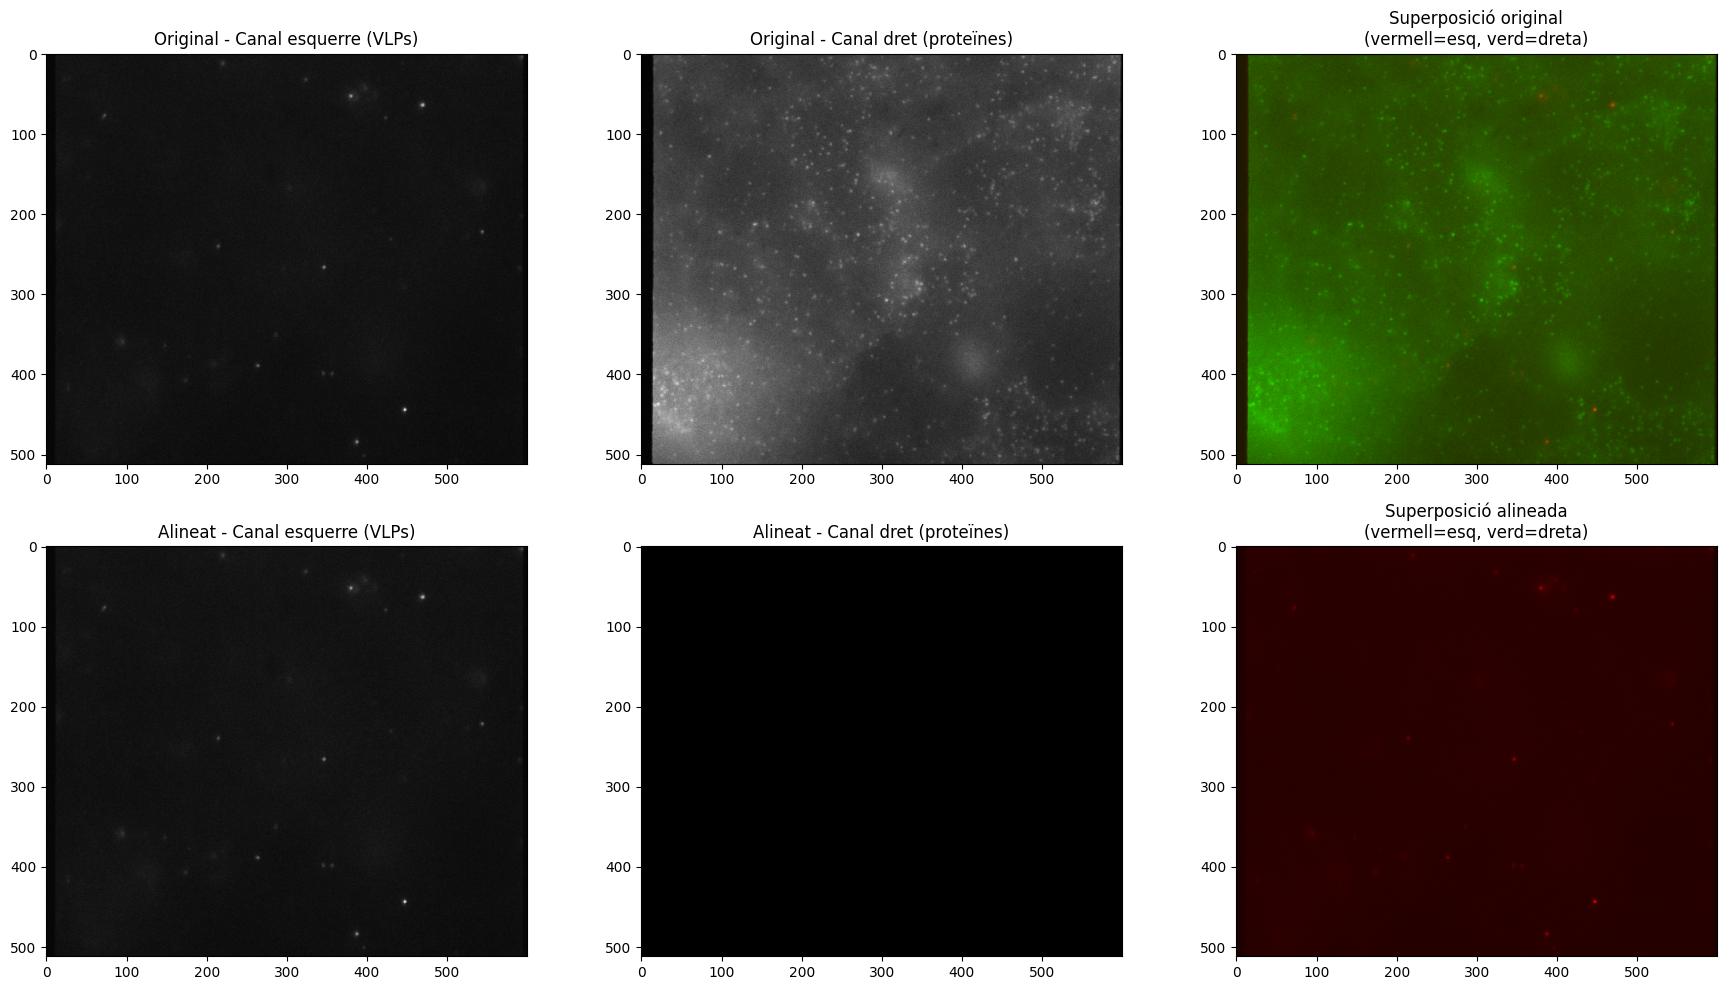

In [30]:
#vull comprovar si és correcte
import tifffile
import matplotlib.pyplot as plt
import numpy as np
#carrego video original
tif_orig = tifffile.TiffFile('/content/SERIE 03.tif')
orig_frames = [page.asarray() for page in tif_orig.pages]
video_orig = np.array(orig_frames)
tif_orig.close()

#també el alineat
tif_aligned = tifffile.TiffFile('/content/SERIE_03_aligned.tif')
aligned_frames = [page.asarray() for page in tif_aligned.pages]
video_aligned = np.array(aligned_frames)
tif_aligned.close()

#agafo un frame?
frame_idx = 0
frame_orig = video_orig[frame_idx]
frame_aligned = video_aligned[frame_idx]

#separo els canals
ample = frame_orig.shape[1] // 2
orig_left  = frame_orig[:, :ample]
orig_right = frame_orig[:, ample:]
aligned_left  = frame_aligned[:, :ample]
aligned_right = frame_aligned[:, ample:]

#superposicions (vermell: canal esquerre, verd: canal dret)
def make_overlay(left, right):
    overlay = np.zeros((left.shape[0], left.shape[1], 3))
    overlay[..., 0] = left / left.max()    #vermell
    overlay[..., 1] = right / right.max()  #verd
    return overlay

overlay_orig = make_overlay(orig_left, orig_right)
overlay_aligned = make_overlay(aligned_left, aligned_right)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

#fila superior és vídeo original
axes[0, 0].imshow(orig_left, cmap='gray')
axes[0, 0].set_title("Original - Canal esquerre (VLPs)")
axes[0, 1].imshow(orig_right, cmap='gray')
axes[0, 1].set_title("Original - Canal dret (proteïnes)")
axes[0, 2].imshow(overlay_orig)
axes[0, 2].set_title("Superposició original\n(vermell=esq, verd=dreta)")

#fila inferior és vídeo alineat
axes[1, 0].imshow(aligned_left, cmap='gray')
axes[1, 0].set_title("Alineat - Canal esquerre (VLPs)")
axes[1, 1].imshow(aligned_right, cmap='gray')
axes[1, 1].set_title("Alineat - Canal dret (proteïnes)")
axes[1, 2].imshow(overlay_aligned)
axes[1, 2].set_title("Superposició alineada\n(vermell=esq, verd=dreta)")

plt.tight_layout()
plt.show()